In [1]:
import pandas as pd

df = pd.read_csv("student_performance.csv")

print(df.shape)

(14003, 16)


In [2]:
print(df.head())

   StudyHours  Attendance  Resources  Extracurricular  Motivation  Internet  \
0          19          64          1                0           0         1   
1          19          64          1                0           0         1   
2          19          64          1                0           0         1   
3          19          64          1                1           0         1   
4          19          64          1                1           0         1   

   Gender  Age  LearningStyle  OnlineCourses  Discussions  \
0       0   19              2              8            1   
1       0   23              3             16            0   
2       0   28              1             19            0   
3       0   19              2              8            1   
4       0   23              3             16            0   

   AssignmentCompletion  ExamScore  EduTech  StressLevel  FinalGrade  
0                    59         40        0            1           3  
1               

In [3]:
print(df.columns)

Index(['StudyHours', 'Attendance', 'Resources', 'Extracurricular',
       'Motivation', 'Internet', 'Gender', 'Age', 'LearningStyle',
       'OnlineCourses', 'Discussions', 'AssignmentCompletion', 'ExamScore',
       'EduTech', 'StressLevel', 'FinalGrade'],
      dtype='str')


In [4]:
print(df.isnull().sum())

StudyHours              0
Attendance              0
Resources               0
Extracurricular         0
Motivation              0
Internet                0
Gender                  0
Age                     0
LearningStyle           0
OnlineCourses           0
Discussions             0
AssignmentCompletion    0
ExamScore               0
EduTech                 0
StressLevel             0
FinalGrade              0
dtype: int64


In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1534


In [6]:
df.describe()

,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
count,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.00000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000
mean,19.987431,80.194316,1.104406,0.594158,0.905806,0.925516,0.551953,23.532172,1.515461,9.891952,0.60587,74.502535,70.346926,0.709062,1.304363,1.447904
std,5.890637,11.472181,0.697362,0.491072,0.695896,0.262566,0.497311,3.514293,1.112941,6.112801,0.48868,14.632177,17.688113,0.454211,0.785383,1.121550
min,5.000000,60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000,0.000000,0.000000,0.00000,50.000000,40.000000,0.000000,0.000000,0.000000
25%,16.000000,70.000000,1.000000,0.000000,0.000000,1.000000,0.000000,20.000000,1.000000,5.000000,0.00000,62.000000,55.000000,0.000000,1.000000,0.000000
50%,20.000000,80.000000,1.000000,1.000000,1.000000,1.000000,1.000000,24.000000,2.000000,10.000000,1.00000,74.000000,70.000000,1.000000,2.000000,1.000000
75%,24.000000,90.000000,2.000000,1.000000,1.000000,1.000000,1.000000,27.000000,3.000000,15.000000,1.00000,87.000000,86.000000,1.000000,2.000000,2.000000
max,44.000000,100.000000,2.000000,1.000000,2.000000,1.000000,1.000000,29.000000,3.000000,20.000000,1.00000,100.000000,100.000000,1.000000,2.000000,3.000000


In [7]:
df.dtypes


StudyHours              int64
Attendance              int64
Resources               int64
Extracurricular         int64
Motivation              int64
Internet                int64
Gender                  int64
Age                     int64
LearningStyle           int64
OnlineCourses           int64
Discussions             int64
AssignmentCompletion    int64
ExamScore               int64
EduTech                 int64
StressLevel             int64
FinalGrade              int64
dtype: object

In [8]:
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))

Original rows: 14003
Rows after removing duplicates: 12469


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

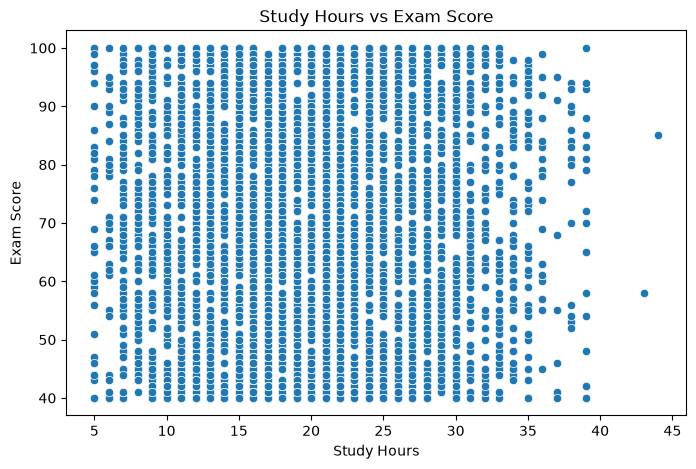

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="StudyHours",
    y="ExamScore"
)

plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.show()

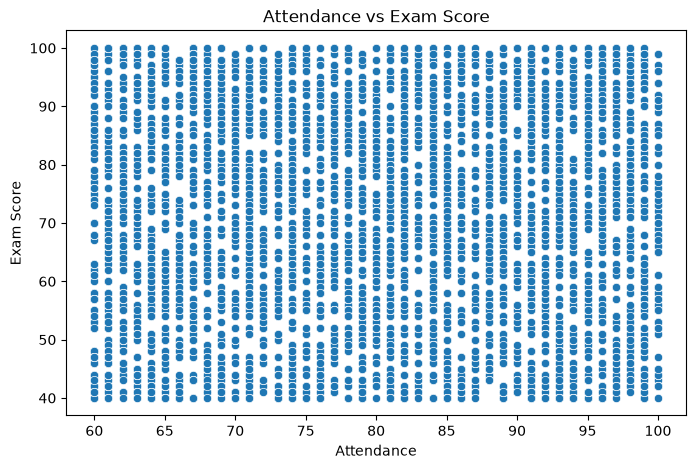

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Attendance",
    y="ExamScore"
)

plt.title("Attendance vs Exam Score")
plt.xlabel("Attendance")
plt.ylabel("Exam Score")

plt.show()

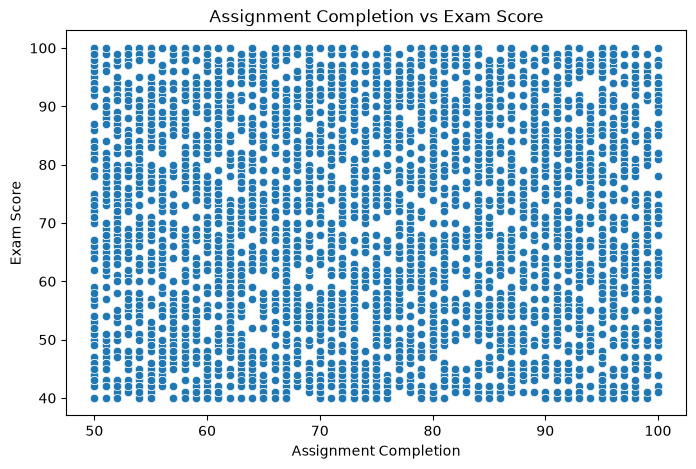

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="AssignmentCompletion",
    y="ExamScore"
)

plt.title("Assignment Completion vs Exam Score")
plt.xlabel("Assignment Completion")
plt.ylabel("Exam Score")

plt.show()

In [13]:
behavior_columns = [
    "StudyHours",
    "Attendance",
    "Resources",
    "Extracurricular",
    "Motivation",
    "Internet",
    "OnlineCourses",
    "Discussions",
    "AssignmentCompletion",
    "EduTech",
    "StressLevel"
]

correlation = df_clean[behavior_columns + ["ExamScore"]].corr()

print(correlation["ExamScore"].sort_values(ascending=False))

ExamScore               1.000000
AssignmentCompletion    0.027402
OnlineCourses           0.020684
EduTech                 0.010311
Resources               0.005119
StudyHours              0.004201
Motivation             -0.003539
Extracurricular        -0.006821
Internet               -0.007342
Attendance             -0.014156
Discussions            -0.031209
StressLevel            -0.034324
Name: ExamScore, dtype: float64


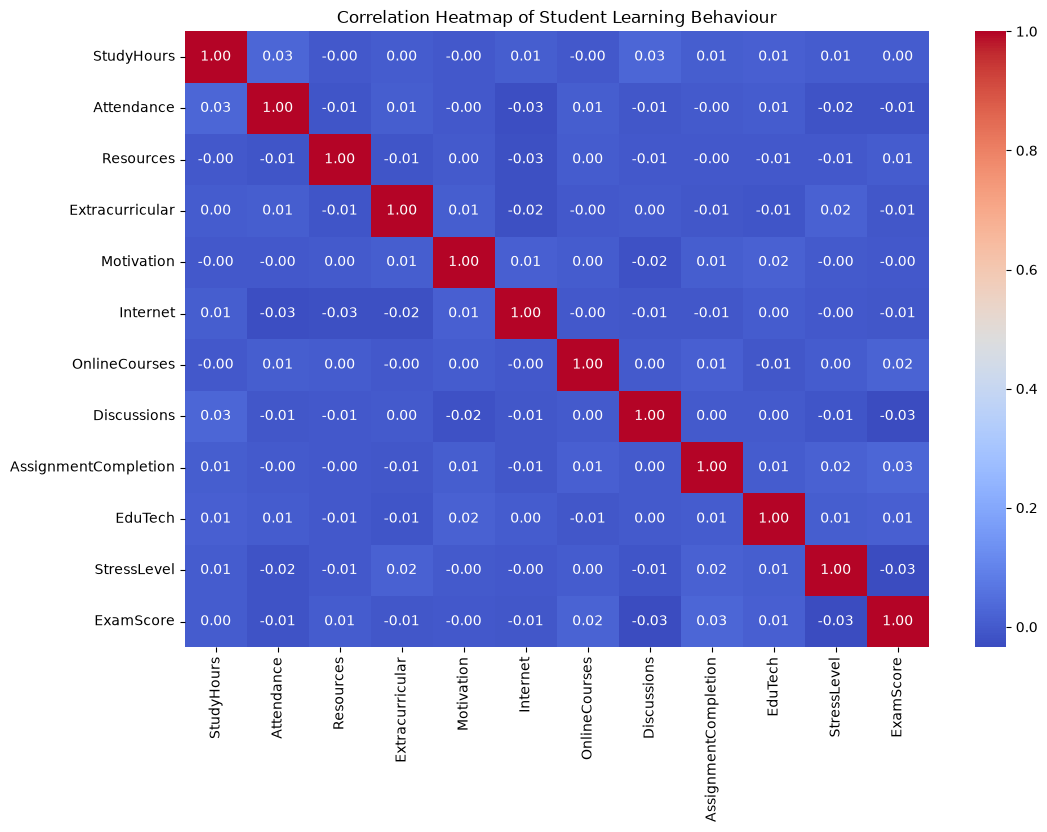

In [14]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Student Learning Behaviour")
plt.show()

In [15]:
exam_correlations = (
    correlation["ExamScore"]
    .drop("ExamScore")
    .sort_values(ascending=False)
)

print(exam_correlations)

AssignmentCompletion    0.027402
OnlineCourses           0.020684
EduTech                 0.010311
Resources               0.005119
StudyHours              0.004201
Motivation             -0.003539
Extracurricular        -0.006821
Internet               -0.007342
Attendance             -0.014156
Discussions            -0.031209
StressLevel            -0.034324
Name: ExamScore, dtype: float64


In [16]:
cluster_features = [
    "StudyHours",
    "Attendance",
    "Resources",
    "Extracurricular",
    "Motivation",
    "Internet",
    "OnlineCourses",
    "Discussions",
    "AssignmentCompletion",
    "EduTech",
    "StressLevel"
]

X = df_clean[cluster_features]

print(X.head())

   StudyHours  Attendance  Resources  Extracurricular  Motivation  Internet  \
0          19          64          1                0           0         1   
1          19          64          1                0           0         1   
2          19          64          1                0           0         1   
3          19          64          1                1           0         1   
4          19          64          1                1           0         1   

   OnlineCourses  Discussions  AssignmentCompletion  EduTech  StressLevel  
0              8            1                    59        0            1  
1             16            0                    90        0            1  
2             19            0                    67        1            1  
3              8            1                    59        0            1  
4             16            0                    90        0            1  


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.17099751 -1.41597738 -0.14254726 -1.18271181 -1.27876066  0.30070606
  -0.30625959  0.80595088 -1.05855583 -1.55410061 -0.38871282]
 [-0.17099751 -1.41597738 -0.14254726 -1.18271181 -1.27876066  0.30070606
   1.00225999 -1.24077041  1.05646018 -1.55410061 -0.38871282]
 [-0.17099751 -1.41597738 -0.14254726 -1.18271181 -1.27876066  0.30070606
   1.49295484 -1.24077041 -0.51274525  0.64345898 -0.38871282]
 [-0.17099751 -1.41597738 -0.14254726  0.84551451 -1.27876066  0.30070606
  -0.30625959  0.80595088 -1.05855583 -1.55410061 -0.38871282]
 [-0.17099751 -1.41597738 -0.14254726  0.84551451 -1.27876066  0.30070606
   1.00225999 -1.24077041  1.05646018 -1.55410061 -0.38871282]]


In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = {}

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores[k] = score

    print("K =", k, "Silhouette Score =", score)

K = 2 Silhouette Score = 0.23263331089775138
K = 3 Silhouette Score = 0.09286072733742028
K = 4 Silhouette Score = 0.11346159853426813
K = 5 Silhouette Score = 0.09799011059468829
K = 6 Silhouette Score = 0.10327852838213912


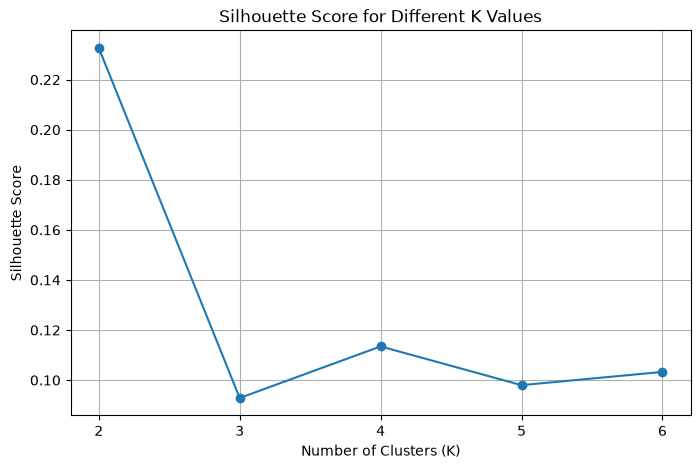

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(silhouette_scores.keys()),
    list(silhouette_scores.values()),
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(range(2, 7))
plt.grid(True)

plt.show()

In [20]:
best_k = max(
    silhouette_scores,
    key=silhouette_scores.get
)

print("Selected number of clusters:", best_k)

Selected number of clusters: 2


In [21]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df_clean["BehaviourCluster"] = kmeans.fit_predict(X_scaled)

In [22]:
cluster_counts = df_clean["BehaviourCluster"].value_counts().sort_index()

print(cluster_counts)

BehaviourCluster
0    11435
1     1034
Name: count, dtype: int64


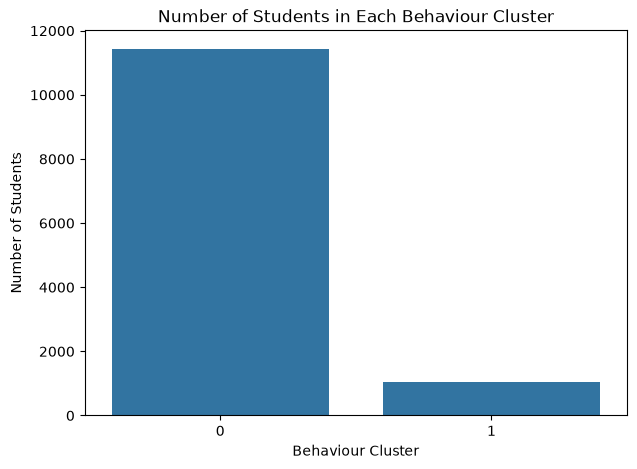

In [23]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.xlabel("Behaviour Cluster")
plt.ylabel("Number of Students")
plt.title("Number of Students in Each Behaviour Cluster")

plt.show()

In [24]:
cluster_profile = df_clean.groupby("BehaviourCluster")[cluster_features].mean()

print(cluster_profile)



                  StudyHours  Attendance  Resources  Extracurricular  \
BehaviourCluster                                                       
0                  20.049497   80.147267   1.096021         0.579537   
1                  19.867505   81.256286   1.160542         0.622824   

                  Motivation  Internet  OnlineCourses  Discussions  \
BehaviourCluster                                                     
0                   0.909926       1.0       9.867599     0.605247   
1                   0.879110       0.0       9.925532     0.617021   

                  AssignmentCompletion   EduTech  StressLevel  
BehaviourCluster                                               
0                            74.484128  0.707827     1.304591  
1                            74.860735  0.700193     1.313346  


In [25]:
cluster_exam = df_clean.groupby("BehaviourCluster")["ExamScore"].agg(
    ["count", "mean", "min", "max"]
)

print(cluster_exam)

                  count       mean  min  max
BehaviourCluster                            
0                 11435  70.271622   40  100
1                  1034  70.742747   40  100


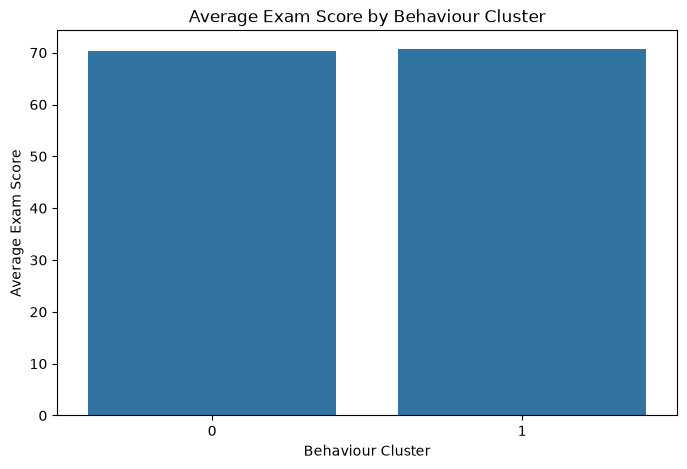

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_exam.index,
    y=cluster_exam["mean"]
)

plt.xlabel("Behaviour Cluster")
plt.ylabel("Average Exam Score")
plt.title("Average Exam Score by Behaviour Cluster")

plt.show()

In [27]:
import os

os.makedirs("project_output", exist_ok=True)

In [28]:
df_clean.to_csv(
    "project_output/clustered_students.csv",
    index=False
)

In [29]:
cluster_profile.to_csv(
    "project_output/cluster_profiles.csv"
)

In [30]:
cluster_exam.to_csv(
    "project_output/cluster_exam_score.csv"
)

In [31]:
overall_mean = df_clean[cluster_features].mean()

print(overall_mean)

StudyHours              20.034405
Attendance              80.239233
Resources                1.101371
Extracurricular          0.583126
Motivation               0.907370
Internet                 0.917074
OnlineCourses            9.872404
Discussions              0.606223
AssignmentCompletion    74.515358
EduTech                  0.707194
StressLevel              1.305317
dtype: float64


In [32]:
cluster_comparison = cluster_profile - overall_mean

print(cluster_comparison)

                  StudyHours  Attendance  Resources  Extracurricular  \
BehaviourCluster                                                       
0                   0.015092   -0.091966   -0.00535        -0.003590   
1                  -0.166900    1.017053    0.05917         0.039698   

                  Motivation  Internet  OnlineCourses  Discussions  \
BehaviourCluster                                                     
0                   0.002555  0.082926      -0.004804    -0.000976   
1                  -0.028260 -0.917074       0.053128     0.010798   

                  AssignmentCompletion   EduTech  StressLevel  
BehaviourCluster                                               
0                            -0.031230  0.000633    -0.000726  
1                             0.345377 -0.007000     0.008029  


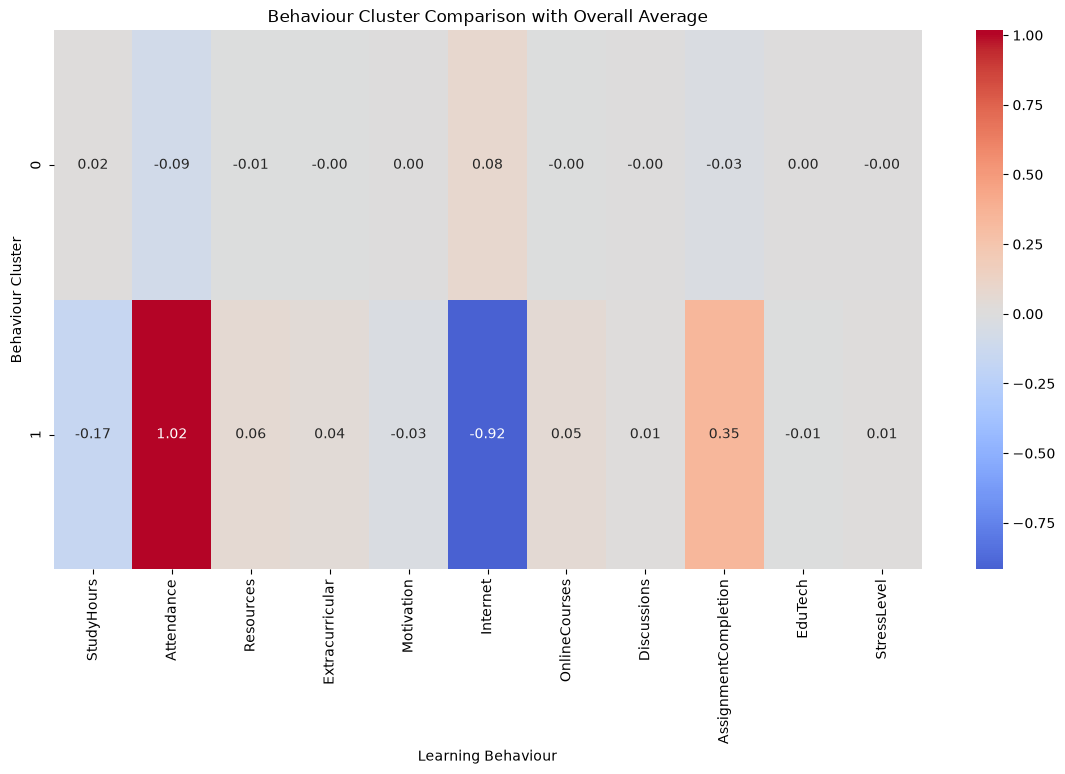

In [33]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    cluster_comparison,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Behaviour Cluster Comparison with Overall Average")
plt.xlabel("Learning Behaviour")
plt.ylabel("Behaviour Cluster")

plt.show()

In [34]:
recommendations = []

for cluster in cluster_profile.index:

    profile = cluster_profile.loc[cluster]
    suggestions = []

    if profile["Attendance"] < overall_mean["Attendance"]:
        suggestions.append(
            "Encourage regular attendance and attendance monitoring."
        )

    if profile["StudyHours"] < overall_mean["StudyHours"]:
        suggestions.append(
            "Encourage a structured weekly study plan."
        )

    if profile["AssignmentCompletion"] < overall_mean["AssignmentCompletion"]:
        suggestions.append(
            "Use smaller assignment milestones, reminders and progress tracking."
        )

    if profile["Discussions"] < overall_mean["Discussions"]:
        suggestions.append(
            "Increase interactive activities and group discussions."
        )

    if profile["OnlineCourses"] < overall_mean["OnlineCourses"]:
        suggestions.append(
            "Provide guided online learning resources."
        )

    if profile["Motivation"] < overall_mean["Motivation"]:
        suggestions.append(
            "Use goal-setting and regular progress feedback."
        )

    if profile["StressLevel"] > overall_mean["StressLevel"]:
        suggestions.append(
            "Review workload and provide appropriate academic support."
        )

    if not suggestions:
        suggestions.append(
            "Behaviour values are close to the overall average; continue monitoring and provide general academic support."
        )

    recommendations.append({
        "BehaviourCluster": cluster,
        "Recommendations": " ".join(suggestions)
    })

recommendations_df = pd.DataFrame(recommendations)

print(recommendations_df)

   BehaviourCluster                                    Recommendations
0                 0  Encourage regular attendance and attendance mo...
1                 1  Encourage a structured weekly study plan. Use ...


In [35]:
recommendations_df.to_csv(
    "project_output/teaching_recommendations.csv",
    index=False
)

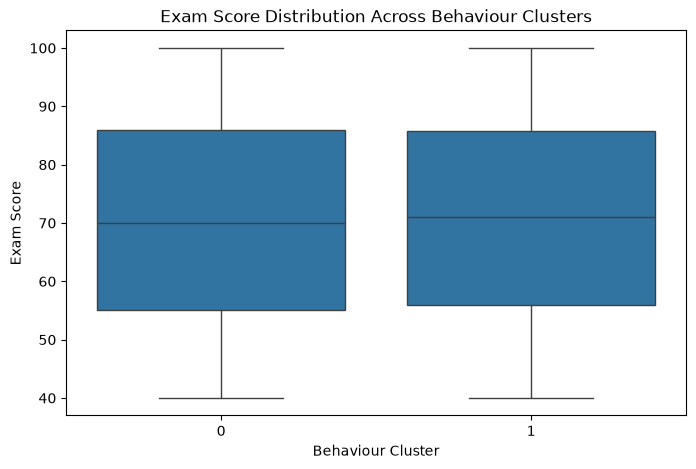

In [36]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="BehaviourCluster",
    y="ExamScore"
)

plt.title("Exam Score Distribution Across Behaviour Clusters")
plt.xlabel("Behaviour Cluster")
plt.ylabel("Exam Score")

plt.show()

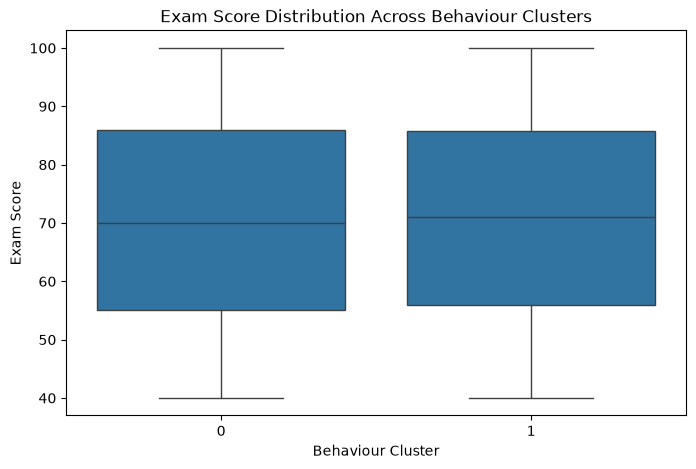

In [37]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="BehaviourCluster",
    y="ExamScore"
)

plt.title("Exam Score Distribution Across Behaviour Clusters")
plt.xlabel("Behaviour Cluster")
plt.ylabel("Exam Score")

plt.savefig(
    "project_output/exam_score_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
print("Selected K:", best_k)
print("\nCluster Exam Score:")
print(cluster_exam)

Selected K: 2

Cluster Exam Score:
                  count       mean  min  max
BehaviourCluster                            
0                 11435  70.271622   40  100
1                  1034  70.742747   40  100


In [39]:
import joblib
import os

os.makedirs("project_output", exist_ok=True)

joblib.dump(
    kmeans,
    "project_output/student_behaviour_clustering.pkl"
)

joblib.dump(
    scaler,
    "project_output/student_behaviour_scaler.pkl"
)

print("K-Means model saved successfully!")
print("Scaler saved successfully!")

K-Means model saved successfully!
Scaler saved successfully!


In [40]:
correlation.to_csv(
    "project_output/correlation_matrix.csv"
)

print("Correlation matrix saved successfully!")

Correlation matrix saved successfully!


In [41]:
import os

print(os.listdir("project_output"))

['clustered_students.csv', 'cluster_exam_score.csv', 'cluster_profiles.csv', 'correlation_matrix.csv', 'exam_score_by_cluster.png', 'student_behaviour_clustering.pkl', 'student_behaviour_scaler.pkl', 'teaching_recommendations.csv']
